In [13]:
import pandas as pd
import matplotlib.pyplot as plt

print("Our fertility analysis project is starting")

Our fertility analysis project is starting


In [15]:
import os

os.listdir("../data")

['.DS_Store', 'fertility_france.xlsx', 'fertility_sweden.xlsx']

In [17]:
import pandas as pd

# Define the paths to our Excel files
france_file = "../data/fertility_france.xlsx"
sweden_file = "../data/fertility_sweden.xlsx"

# Open both Excel files
france_excel = pd.ExcelFile(france_file)
sweden_excel = pd.ExcelFile(sweden_file)

# Display the worksheet names
print("FRANCE:")
print(france_excel.sheet_names)

print("\nSWEDEN:")
print(sweden_excel.sheet_names)

FRANCE:
['Summary', '10-14', '15-19', '20-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50+']

SWEDEN:
['Summary', '10-14', '15-19', '20-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50+']


In [23]:
import pandas as pd

# FRANCE

france_file = "../data/fertility_france.xlsx"

# Age groups in chronological order
age_groups = [
    "10-14", "15-19", "20-24",
    "25-29", "30-34", "35-39",
    "40-44", "45-49", "50+"
]

france_data = []

for age in age_groups:

    # Read the worksheet corresponding to this age group
    df = pd.read_excel(
        france_file,
        sheet_name=age,
        header=None
    )

    # Extract years and fertility rates
    years = pd.to_numeric(df.iloc[9, 1::2], errors="coerce")
    rates = pd.to_numeric(df.iloc[11, 1::2], errors="coerce")

    # Create a clean DataFrame for this age group
    clean_df = pd.DataFrame({
        "Year": years.values,
        "Rate": rates.values
    })

    # Remove rows without a valid year
    clean_df = clean_df.dropna(subset=["Year"])

    # Convert years to integers
    clean_df["Year"] = clean_df["Year"].astype(int)

    # Add the age group and country
    clean_df["Age_group"] = age
    clean_df["Country"] = "France"

    # Store the cleaned data
    france_data.append(clean_df)

# Combine all nine age groups
france_clean = pd.concat(france_data, ignore_index=True)

# Display the first 10 rows
display(france_clean.head(10))

,Year,Rate,Age_group,Country
0,1990,NaN,10-14,France
1,1991,NaN,10-14,France
2,1992,NaN,10-14,France
3,1993,NaN,10-14,France
4,1994,NaN,10-14,France
5,1995,NaN,10-14,France
6,1996,NaN,10-14,France
7,1997,NaN,10-14,France
8,1998,0.00011,10-14,France
9,1999,0.00011,10-14,France


In [25]:
print("Dataset dimensions:", france_clean.shape)

print("\nObservations by age group:")
print(france_clean.groupby("Age_group")["Rate"].count())

print("\nFirst and last year:")
print(france_clean["Year"].min(), france_clean["Year"].max())

Dataset dimensions: (315, 4)

Observations by age group:
Age_group
10-14    27
15-19    27
20-24    27
25-29    27
30-34    27
35-39    27
40-44    27
45-49    27
50+      27
Name: Rate, dtype: int64

First and last year:
1990 2024


In [27]:
france_clean.groupby("Age_group").agg(
    First_year=("Year", lambda x: x.min()),
    Last_year=("Year", lambda x: x.max()),
    Available_rates=("Rate", "count")
)

,First_year,Last_year,Available_rates
Age_group,,,
10-14,1990,2024,27
15-19,1990,2024,27
20-24,1990,2024,27
25-29,1990,2024,27
30-34,1990,2024,27
35-39,1990,2024,27
40-44,1990,2024,27
45-49,1990,2024,27
50+,1990,2024,27


In [29]:
france_clean.dropna(subset=["Rate"]).groupby("Age_group").agg(
    First_available_year=("Year", "min"),
    Last_available_year=("Year", "max")
)

,First_available_year,Last_available_year
Age_group,,
10-14,1998,2024
15-19,1998,2024
20-24,1998,2024
25-29,1998,2024
30-34,1998,2024
35-39,1998,2024
40-44,1998,2024
45-49,1998,2024
50+,1998,2024


In [31]:
# SWEDEN

sweden_file = "../data/fertility_sweden.xlsx"

# Age groups in chronological order
age_groups = [
    "10-14", "15-19", "20-24",
    "25-29", "30-34", "35-39",
    "40-44", "45-49", "50+"
]

sweden_data = []

for age in age_groups:

    # Read the worksheet corresponding to this age group
    df = pd.read_excel(
        sweden_file,
        sheet_name=age,
        header=None
    )

    # Extract years and fertility rates
    years = pd.to_numeric(df.iloc[9, 1::2], errors="coerce")
    rates = pd.to_numeric(df.iloc[11, 1::2], errors="coerce")

    # Create a clean DataFrame for this age group
    clean_df = pd.DataFrame({
        "Year": years.values,
        "Rate": rates.values
    })

    # Remove rows without a valid year
    clean_df = clean_df.dropna(subset=["Year"])

    # Convert years to integers
    clean_df["Year"] = clean_df["Year"].astype(int)

    # Add the age group and country
    clean_df["Age_group"] = age
    clean_df["Country"] = "Sweden"

    # Store the cleaned data
    sweden_data.append(clean_df)

# Combine all nine age groups
sweden_clean = pd.concat(sweden_data, ignore_index=True)

# Display the first 10 rows
display(sweden_clean.head(10))

,Year,Rate,Age_group,Country
0,1990,0.00004,10-14,Sweden
1,1991,0.00003,10-14,Sweden
2,1992,0.00005,10-14,Sweden
3,1993,0.00003,10-14,Sweden
4,1994,0.00002,10-14,Sweden
5,1995,0.00004,10-14,Sweden
6,1996,0.00002,10-14,Sweden
7,1997,0.00002,10-14,Sweden
8,1998,0.00001,10-14,Sweden
9,1999,0.00003,10-14,Sweden


In [33]:
print("Dataset dimensions:", sweden_clean.shape)

print("\nObservations by age group:")
print(sweden_clean.groupby("Age_group")["Rate"].count())

print("\nFirst and last year:")
print(sweden_clean["Year"].min(), sweden_clean["Year"].max())

Dataset dimensions: (315, 4)

Observations by age group:
Age_group
10-14    35
15-19    35
20-24    35
25-29    35
30-34    35
35-39    35
40-44    35
45-49    35
50+      35
Name: Rate, dtype: int64

First and last year:
1990 2024


In [35]:
sweden_clean.groupby("Age_group").agg(
    First_year=("Year", lambda x: x.min()),
    Last_year=("Year", lambda x: x.max()),
    Available_rates=("Rate", "count")
)

,First_year,Last_year,Available_rates
Age_group,,,
10-14,1990,2024,35
15-19,1990,2024,35
20-24,1990,2024,35
25-29,1990,2024,35
30-34,1990,2024,35
35-39,1990,2024,35
40-44,1990,2024,35
45-49,1990,2024,35
50+,1990,2024,35


In [37]:
sweden_clean.dropna(subset=["Rate"]).groupby("Age_group").agg(
    First_available_year=("Year", "min"),
    Last_available_year=("Year", "max")
)

,First_available_year,Last_available_year
Age_group,,
10-14,1990,2024
15-19,1990,2024
20-24,1990,2024
25-29,1990,2024
30-34,1990,2024
35-39,1990,2024
40-44,1990,2024
45-49,1990,2024
50+,1990,2024


In [39]:
for country, data in [("FRANCE", france_clean), ("SWEDEN", sweden_clean)]:

    print(f"\n===== {country} =====")
    print("Dataset dimensions:", data.shape)

    print("\nAvailable observations and year coverage:")

    summary = (
        data.dropna(subset=["Rate"])
        .groupby("Age_group")
        .agg(
            First_available_year=("Year", "min"),
            Last_available_year=("Year", "max"),
            Available_rates=("Rate", "count")
        )
    )

    print(summary.to_string())


===== FRANCE =====
Dataset dimensions: (315, 4)

Available observations and year coverage:
           First_available_year  Last_available_year  Available_rates
Age_group                                                            
10-14                      1998                 2024               27
15-19                      1998                 2024               27
20-24                      1998                 2024               27
25-29                      1998                 2024               27
30-34                      1998                 2024               27
35-39                      1998                 2024               27
40-44                      1998                 2024               27
45-49                      1998                 2024               27
50+                        1998                 2024               27

===== SWEDEN =====
Dataset dimensions: (315, 4)

Available observations and year coverage:
           First_available_year  Last_availabl

In [41]:
# Combine France and Sweden into one DataFrame, for easier analysis 

fertility_data = pd.concat(
    [france_clean, sweden_clean],
    ignore_index=True
)

# Display the first 10 rows
display(fertility_data.head(10))

,Year,Rate,Age_group,Country
0,1990,NaN,10-14,France
1,1991,NaN,10-14,France
2,1992,NaN,10-14,France
3,1993,NaN,10-14,France
4,1994,NaN,10-14,France
5,1995,NaN,10-14,France
6,1996,NaN,10-14,France
7,1997,NaN,10-14,France
8,1998,0.00011,10-14,France
9,1999,0.00011,10-14,France


In [43]:
print("Combined dataset dimensions:", fertility_data.shape)

print("\nObservations by country:")
print(fertility_data.groupby("Country")["Rate"].count())

print("\nMissing values:")
print(fertility_data.isna().sum())

Combined dataset dimensions: (630, 4)

Observations by country:
Country
France    243
Sweden    315
Name: Rate, dtype: int64

Missing values:
Year          0
Rate         72
Age_group     0
Country       0
dtype: int64


In [45]:
# I think we'll just start the analysis from 1998, where both countries start having data
fertility_trends = fertility_data[
    (fertility_data["Year"] >= 1998) &
    (fertility_data["Year"] <= 2024)
]

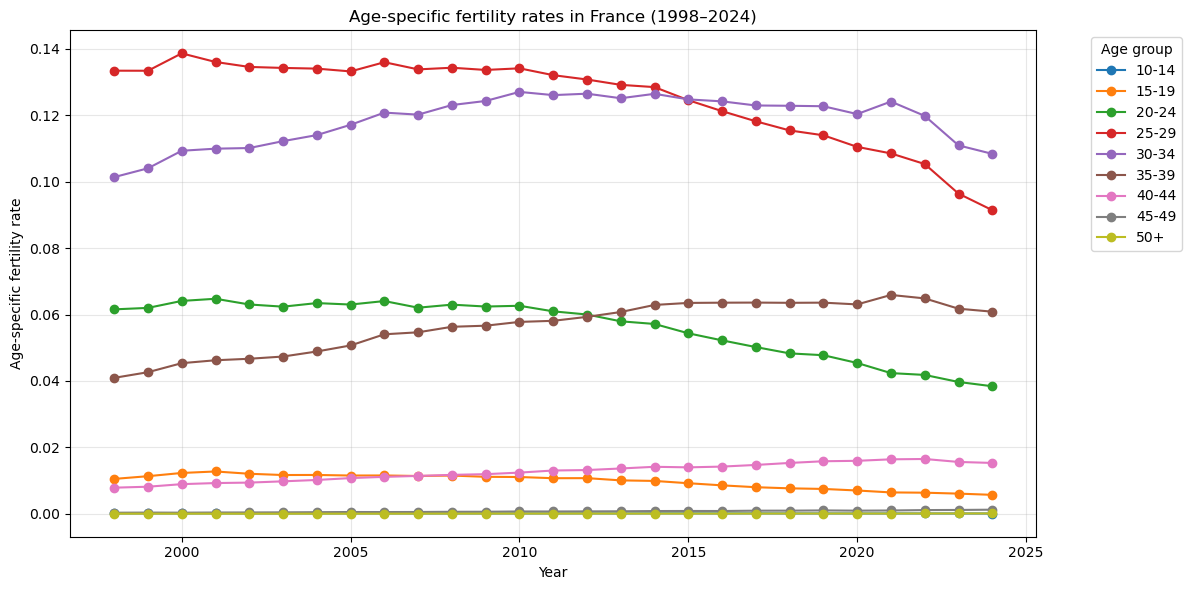

In [47]:
# Just testing with visualisation

import matplotlib.pyplot as plt

# Select France
france_trends = fertility_trends[
    fertility_trends["Country"] == "France"
]

# Organise data for plotting
france_plot = france_trends.pivot(
    index="Year",
    columns="Age_group",
    values="Rate"
)

# Arrange age groups in order
france_plot = france_plot[age_groups]

# Create line chart
france_plot.plot(
    kind="line",
    figsize=(12, 6),
    marker="o"
)

plt.title("Age-specific fertility rates in France (1998–2024)")
plt.xlabel("Year")
plt.ylabel("Age-specific fertility rate")
plt.legend(title="Age group", bbox_to_anchor=(1.05, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

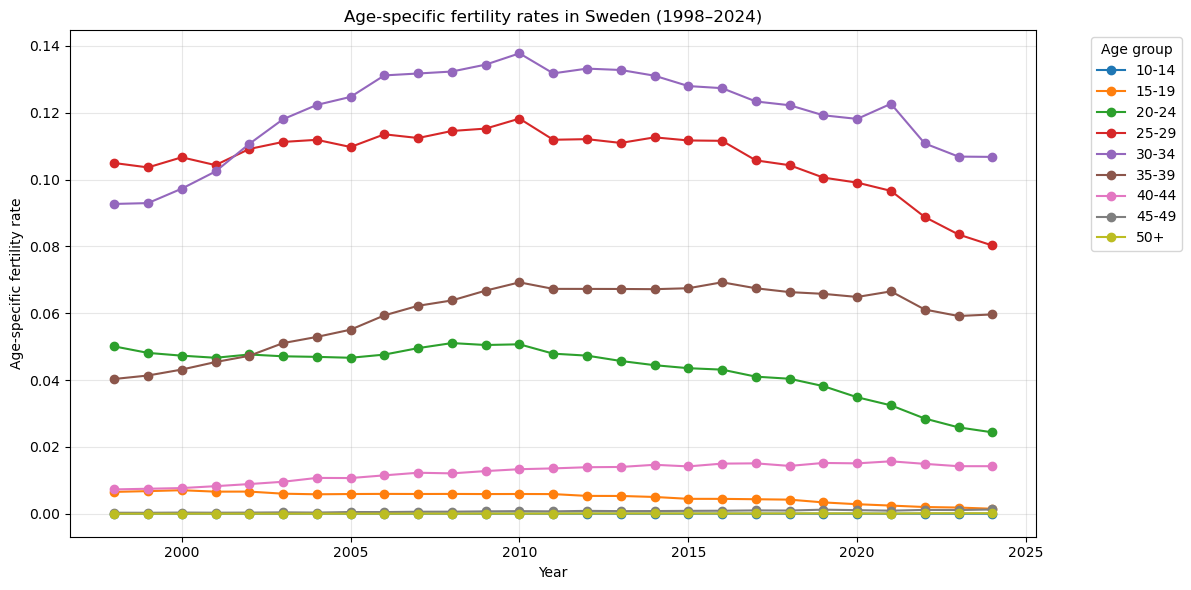

In [49]:
# Same visualisation testing for Sweden

sweden_trends = fertility_trends[
    fertility_trends["Country"] == "Sweden"
]

# Organize data for plotting
sweden_plot = sweden_trends.pivot(
    index="Year",
    columns="Age_group",
    values="Rate"
)

# Arrange age groups in order
sweden_plot = sweden_plot[age_groups]

# Create line chart
sweden_plot.plot(
    kind="line",
    figsize=(12, 6),
    marker="o"
)

plt.title("Age-specific fertility rates in Sweden (1998–2024)")
plt.xlabel("Year")
plt.ylabel("Age-specific fertility rate")
plt.legend(title="Age group", bbox_to_anchor=(1.05, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()